# Curve Fitting & Custom Parameter Estimation (`softpotato.analytical.fitting`)

## 1. Goal

Use `softpotato.analytical.fitting` to extract physical parameters and 95% confidence intervals from noisy electrochemical datasets—both with specialized domain fitters (`fit_cottrell`, `fit_koutecky_levich`, `fit_butler_volmer`) and with the general-purpose `fit_curve()` API for custom nonlinear models.

## 2. Specialized Domain Fitters

We generate synthetic noisy data for three canonical experiments and recover the underlying physical parameters with `stderr` and $R^2$ goodness-of-fit metrics.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

from softpotato import analytical as spa

rng = np.random.default_rng(42)

# Shared parameters
n = 1
D_true = 8.5e-10
c_bulk = 1.0
area = 7.07e-6
nu = 1.0e-6
T = 298.15

# 1. Cottrell fit
t_ca = np.linspace(0.05, 4.0, 60)
i_ca = spa.cottrell(t_ca, n=n, D=D_true, c_bulk=c_bulk, area=area) + rng.normal(
    0.0, 2.0e-7, size=t_ca.size
)
ca_fit = spa.fit_cottrell(t_ca, i_ca, n=n, area=area, c_bulk=c_bulk)
print(f"Cottrell fit: D = {ca_fit.d:.3e} +/- {ca_fit.d_stderr:.2e} m^2/s (true {D_true:.2e}), R^2 = {ca_fit.r_squared:.5f}")

# 2. Koutecky-Levich fit
rpm = np.array([400, 625, 900, 1225, 1600, 2025, 2500], dtype=float)
i_k_true = 1.0e-4  # 100 uA (mixed kinetic-diffusion regime)
i_kl = spa.koutecky_levich(
    rpm=rpm, i_k=i_k_true, n=n, D=D_true, c_bulk=c_bulk, area=area, nu=nu
) + rng.normal(0.0, 3.0e-7, size=rpm.size)
kl_fit = spa.fit_koutecky_levich(
    i_kl, rpm=rpm, method="nonlinear", n=n, area=area, c_bulk=c_bulk, nu=nu
)
print(f"K-L fit:      D = {kl_fit.d:.3e} m^2/s, I_k = {kl_fit.i_k*1e6:.2f} uA (true {i_k_true*1e6:.1f} uA), R^2 = {kl_fit.r_squared:.5f}")

# 3. Butler-Volmer fit
eta = np.linspace(-0.18, 0.18, 75)
i_bv = spa.butler_volmer(eta, i0=1.2e-5, alpha=0.42, n=n, T=T) + rng.normal(
    0.0, 8.0e-7, size=eta.size
)
bv_fit = spa.fit_butler_volmer(eta, i_bv, n=n, T=T)
print(f"B-V fit:      I0 = {bv_fit.i0*1e6:.2f} uA, alpha = {bv_fit.alpha:.3f}, R^2 = {bv_fit.r_squared:.5f}")

Cottrell fit: D = 8.504e-10 +/- 2.71e-12 m^2/s (true 8.50e-10), R^2 = 0.99955
K-L fit:      D = 8.226e-10 m^2/s, I_k = 105.25 uA (true 100.0 uA), R^2 = 0.99889
B-V fit:      I0 = 12.01 uA, alpha = 0.420, R^2 = 0.99999


## 3. Custom Nonlinear Model Fitting with `fit_curve()`

In real potential-step experiments, the measured current at short times is a superposition of Faradaic Cottrell diffusion and non-Faradaic double-layer charging:

$$
I(t) = \frac{k_{\text{Cot}}}{\sqrt{t}} + I_{\text{dl}} \exp\left(-\frac{t}{\tau_{\text{RC}}}\right)
$$

We use `spa.fit_curve()` with parameter bounds and `param_names` to deconvolve both contributions and inspect the residuals.

  k_cot    = 1.1191e-05 +/- 7.66e-08
  I_dl     = 1.4799e-04 +/- 1.78e-06
  tau_rc   = 2.5241e-02 +/- 3.71e-04
  R^2      = 0.998551


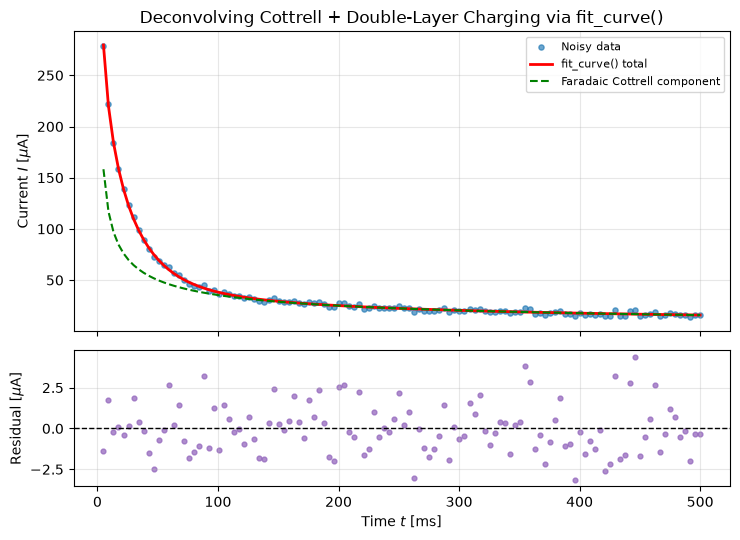

In [2]:
def cottrell_plus_dl(t_arr: np.ndarray, k_cot: float, i_dl: float, tau_rc: float) -> np.ndarray:
    return k_cot / np.sqrt(t_arr) + i_dl * np.exp(-t_arr / tau_rc)


t_exp = np.linspace(0.005, 0.5, 120)
k_true = n * 96485.3321 * area * c_bulk * np.sqrt(D_true / np.pi)
i_dl_true = 1.5e-4
tau_true = 0.025

i_exp = cottrell_plus_dl(t_exp, k_true, i_dl_true, tau_true) + rng.normal(
    0.0, 1.5e-6, size=t_exp.size
)

res = spa.fit_curve(
    cottrell_plus_dl,
    t_exp,
    i_exp,
    p0=[k_true * 0.8, 1.0e-4, 0.02],
    bounds=([0.0, 0.0, 1e-4], [1.0, 1.0, 1.0]),
    param_names=["k_cot", "I_dl", "tau_rc"],
)

for name, val in res.params.items():
    print(f"  {name:<8s} = {val:.4e} +/- {res.stderr[name]:.2e}")
print(f"  R^2      = {res.r_squared:.6f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.5, 5.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax1.scatter(t_exp * 1e3, i_exp * 1e6, s=14, alpha=0.65, label="Noisy data")
ax1.plot(t_exp * 1e3, res.y_fit * 1e6, "r-", lw=2, label="fit_curve() total")
ax1.plot(
    t_exp * 1e3,
    (res.params["k_cot"] / np.sqrt(t_exp)) * 1e6,
    "g--",
    lw=1.5,
    label="Faradaic Cottrell component",
)
ax1.set_ylabel(r"Current $I$ [$\mu$A]")
ax1.set_title("Deconvolving Cottrell + Double-Layer Charging via fit_curve()")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

ax2.scatter(t_exp * 1e3, res.residuals * 1e6, s=12, color="tab:purple", alpha=0.75)
ax2.axhline(0.0, color="k", lw=1, ls="--")
ax2.set_xlabel("Time $t$ [ms]")
ax2.set_ylabel(r"Residual [$\mu$A]")
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

## Key Takeaways

- Specialized fitters (`fit_cottrell`, `fit_koutecky_levich`, `fit_butler_volmer`) return structured dataclasses with `stderr`, `ci95`, and `r_squared`.
- `fit_curve()` wraps `scipy.optimize.curve_fit` with named parameters (`param_names`), `bounds`, and a unified `FitResult` container for arbitrary electrochemical models.